In [17]:
import pandas as pd

# Load dataset
df = pd.read_csv('features_3_sec.csv')

# Print shape and column names
print("Dataset shape:", df.shape)
print("\nColumns:\n", df.columns.tolist())

# Display 5 random samples
print("\nRandom Samples:")
print(df.sample(5))


Dataset shape: (9990, 60)

Columns:
 ['filename', 'length', 'chroma_stft_mean', 'chroma_stft_var', 'rms_mean', 'rms_var', 'spectral_centroid_mean', 'spectral_centroid_var', 'spectral_bandwidth_mean', 'spectral_bandwidth_var', 'rolloff_mean', 'rolloff_var', 'zero_crossing_rate_mean', 'zero_crossing_rate_var', 'harmony_mean', 'harmony_var', 'perceptr_mean', 'perceptr_var', 'tempo', 'mfcc1_mean', 'mfcc1_var', 'mfcc2_mean', 'mfcc2_var', 'mfcc3_mean', 'mfcc3_var', 'mfcc4_mean', 'mfcc4_var', 'mfcc5_mean', 'mfcc5_var', 'mfcc6_mean', 'mfcc6_var', 'mfcc7_mean', 'mfcc7_var', 'mfcc8_mean', 'mfcc8_var', 'mfcc9_mean', 'mfcc9_var', 'mfcc10_mean', 'mfcc10_var', 'mfcc11_mean', 'mfcc11_var', 'mfcc12_mean', 'mfcc12_var', 'mfcc13_mean', 'mfcc13_var', 'mfcc14_mean', 'mfcc14_var', 'mfcc15_mean', 'mfcc15_var', 'mfcc16_mean', 'mfcc16_var', 'mfcc17_mean', 'mfcc17_var', 'mfcc18_mean', 'mfcc18_var', 'mfcc19_mean', 'mfcc19_var', 'mfcc20_mean', 'mfcc20_var', 'label']

Random Samples:
                filename  len

In [18]:

import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle



# Shuffle dataset (optional but good practice)
df = shuffle(df, random_state=42).reset_index(drop=True)

# Display shape and column info
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

# --- STEP 1: Drop unnecessary columns if any (like filename) ---
if 'filename' in df.columns:
    df = df.drop('filename', axis=1)

# --- STEP 2: Separate features and labels ---
X = df.drop('label', axis=1)  # assuming 'label' is the genre column
y = df['label']

# --- STEP 3: Encode labels to numeric values ---
le = LabelEncoder()
y_encoded = le.fit_transform(y)  # genres will become integers 0–9

# --- STEP 4: Feature scaling ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- STEP 5: Train/Test Split (80/20) ---
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Confirm shapes
print(f"\nTrain set: {X_train.shape}, Test set: {X_test.shape}")
print(f"Encoded genre labels: {np.unique(y_encoded)}")
print(f"Label classes: {le.classes_}")


Shape: (9990, 60)
Columns: ['filename', 'length', 'chroma_stft_mean', 'chroma_stft_var', 'rms_mean', 'rms_var', 'spectral_centroid_mean', 'spectral_centroid_var', 'spectral_bandwidth_mean', 'spectral_bandwidth_var', 'rolloff_mean', 'rolloff_var', 'zero_crossing_rate_mean', 'zero_crossing_rate_var', 'harmony_mean', 'harmony_var', 'perceptr_mean', 'perceptr_var', 'tempo', 'mfcc1_mean', 'mfcc1_var', 'mfcc2_mean', 'mfcc2_var', 'mfcc3_mean', 'mfcc3_var', 'mfcc4_mean', 'mfcc4_var', 'mfcc5_mean', 'mfcc5_var', 'mfcc6_mean', 'mfcc6_var', 'mfcc7_mean', 'mfcc7_var', 'mfcc8_mean', 'mfcc8_var', 'mfcc9_mean', 'mfcc9_var', 'mfcc10_mean', 'mfcc10_var', 'mfcc11_mean', 'mfcc11_var', 'mfcc12_mean', 'mfcc12_var', 'mfcc13_mean', 'mfcc13_var', 'mfcc14_mean', 'mfcc14_var', 'mfcc15_mean', 'mfcc15_var', 'mfcc16_mean', 'mfcc16_var', 'mfcc17_mean', 'mfcc17_var', 'mfcc18_mean', 'mfcc18_var', 'mfcc19_mean', 'mfcc19_var', 'mfcc20_mean', 'mfcc20_var', 'label']

Train set: (7992, 58), Test set: (1998, 58)
Encoded gen


Training XGBoost...

📊 XGBoost Accuracy: 0.8793793793793794

📊 : 0.8793793793793794

Training Random Forest incrementally...


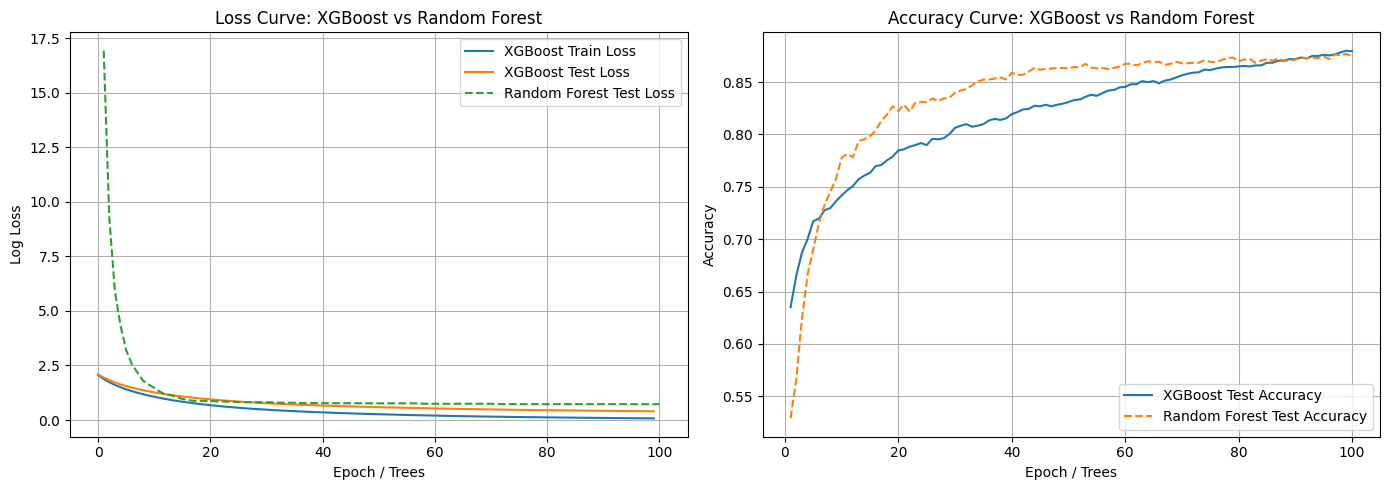

In [19]:
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss
import matplotlib.pyplot as plt
import numpy as np

# === XGBoost === #
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

params = {
    'objective': 'multi:softprob',
    'num_class': len(np.unique(y_train)),
    'max_depth': 6,
    'eta': 0.1,
    'eval_metric': 'mlogloss',
    'seed': 42
}

evals_result = {}

print("\nTraining XGBoost...")
xgb_model = xgb.train(
    params=params,
    dtrain=dtrain,
    num_boost_round=100,
    evals=[(dtrain, 'train'), (dtest, 'test')],
    evals_result=evals_result,
    verbose_eval=False
)

# Predictions for final epoch
y_pred_proba_xgb = xgb_model.predict(dtest)
y_pred_xgb = np.argmax(y_pred_proba_xgb, axis=1)
acc_xgb = accuracy_score(y_test, y_pred_xgb)

print("\n📊 XGBoost Accuracy:", acc_xgb)
print("\n📊 :", acc_xgb)
# === Random Forest (Simulated Epochs) === #
print("\nTraining Random Forest incrementally...")
rf_accuracies = []
rf_losses = []

for n_estimators in range(1, 101):
    rf_model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=None,
        warm_start=True,
        random_state=42
    )
    rf_model.fit(X_train, y_train)

    y_pred_proba_rf = rf_model.predict_proba(X_test)
    y_pred_rf = np.argmax(y_pred_proba_rf, axis=1)

    acc = accuracy_score(y_test, y_pred_rf)
    loss = log_loss(y_test, y_pred_proba_rf)

    rf_accuracies.append(acc)
    rf_losses.append(loss)

# === Plotting === #
epochs = range(1, 101)

plt.figure(figsize=(14, 5))

# XGBoost Loss
plt.subplot(1, 2, 1)
plt.plot(evals_result['train']['mlogloss'], label='XGBoost Train Loss')
plt.plot(evals_result['test']['mlogloss'], label='XGBoost Test Loss')
plt.plot(epochs, rf_losses, label='Random Forest Test Loss', linestyle='--')
plt.xlabel("Epoch / Trees")
plt.ylabel("Log Loss")
plt.title("Loss Curve: XGBoost vs Random Forest")
plt.legend()
plt.grid(True)

# Accuracy
plt.subplot(1, 2, 2)
xgb_test_preds = np.argmax(xgb_model.predict(dtest), axis=1)
xgb_acc = [accuracy_score(y_test, np.argmax(xgb_model.predict(xgb.DMatrix(X_test), iteration_range=(0, i+1)), axis=1)) for i in range(100)]
plt.plot(epochs, xgb_acc, label='XGBoost Test Accuracy')
plt.plot(epochs, rf_accuracies, label='Random Forest Test Accuracy', linestyle='--')
plt.xlabel("Epoch / Trees")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve: XGBoost vs Random Forest")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [6]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 386.6/386.6 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.9/231.9 kB 13.8 MB/s eta 0:00:00


In [20]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define Enhanced MLP Model with Multiple Layers, Swish Activation, and L2 Regularization
class EnhancedMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes, dropout_rate):
        super(EnhancedMLP, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, hidden_dim // 2)
        self.bn3 = nn.BatchNorm1d(hidden_dim // 2)
        self.out = nn.Linear(hidden_dim // 2, num_classes)

        # Dropout layers
        self.dropout = nn.Dropout(dropout_rate)

    def forward(self, x):
        x = F.silu(self.bn1(self.fc1(x)))  # Swish activation function
        x = self.dropout(x)
        x = F.silu(self.bn2(self.fc2(x)))
        x = self.dropout(x)
        x = F.silu(self.bn3(self.fc3(x)))
        x = self.out(x)
        return x

# Optimizer setup with L2 regularization (weight decay)
def get_optimizer(model, lr, weight_decay=1e-4):
    return optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

# Learning rate scheduler (Cosine Annealing)
def get_lr_scheduler(optimizer):
    return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)

# Optuna objective function
def objective(trial):
    hidden_dim = trial.suggest_int('hidden_dim', 128, 1024)
    dropout_rate = trial.suggest_float('dropout_rate', 0.2, 0.5)
    lr = trial.suggest_float('lr', 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128])

    # Load dataset and prepare dataloaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=256)

    # Initialize model
    model = EnhancedMLP(X_train.shape[1], hidden_dim, len(np.unique(y)), dropout_rate).to(device)
    optimizer = get_optimizer(model, lr)
    scheduler = get_lr_scheduler(optimizer)
    criterion = nn.CrossEntropyLoss()

    # Training loop
    for epoch in range(30):  # Set higher epochs for more thorough training
        model.train()
        for xb, yb in train_loader:
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
        scheduler.step()  # Update learning rate

    # Evaluation
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            preds = model(xb).argmax(dim=1)
            all_preds.extend(preds.tolist())
            all_labels.extend(yb.tolist())

    return accuracy_score(all_labels, all_preds)

# Run the Optuna study
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)

print("Best Trial:")
print(study.best_trial)


[I 2025-05-01 19:25:27,373] A new study created in memory with name: no-name-c926e3fa-9cd0-4c91-8913-8eedcc296f2d
[I 2025-05-01 19:25:42,469] Trial 0 finished with value: 0.79 and parameters: {'hidden_dim': 898, 'dropout_rate': 0.43079437587009883, 'lr': 0.002368954658717232, 'batch_size': 32}. Best is trial 0 with value: 0.79.
[I 2025-05-01 19:25:48,051] Trial 1 finished with value: 0.82 and parameters: {'hidden_dim': 437, 'dropout_rate': 0.2523619973230676, 'lr': 0.0011079158520095511, 'batch_size': 32}. Best is trial 1 with value: 0.82.
[I 2025-05-01 19:25:49,660] Trial 2 finished with value: 0.815 and parameters: {'hidden_dim': 236, 'dropout_rate': 0.2881977638106083, 'lr': 0.0022277209407967446, 'batch_size': 128}. Best is trial 1 with value: 0.82.
[I 2025-05-01 19:26:06,859] Trial 3 finished with value: 0.83 and parameters: {'hidden_dim': 966, 'dropout_rate': 0.4478080381717998, 'lr': 0.0002980913891336961, 'batch_size': 32}. Best is trial 3 with value: 0.83.
[I 2025-05-01 19:26:

Best Trial:
FrozenTrial(number=13, state=1, values=[0.845], datetime_start=datetime.datetime(2025, 5, 1, 19, 27, 5, 221613), datetime_complete=datetime.datetime(2025, 5, 1, 19, 27, 14, 358969), params={'hidden_dim': 1010, 'dropout_rate': 0.313540631366658, 'lr': 0.00042225414590705407, 'batch_size': 128}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'hidden_dim': IntDistribution(high=1024, log=False, low=128, step=1), 'dropout_rate': FloatDistribution(high=0.5, log=False, low=0.2, step=None), 'lr': FloatDistribution(high=0.01, log=True, low=0.0001, step=None), 'batch_size': CategoricalDistribution(choices=(32, 64, 128))}, trial_id=13, value=None)


Epoch 1/100 - Train Loss: 1.6822 - Train Accuracy: 0.4050 - Validation Accuracy: 0.6050
Epoch 2/100 - Train Loss: 1.1019 - Train Accuracy: 0.6550 - Validation Accuracy: 0.6900
Epoch 3/100 - Train Loss: 0.9350 - Train Accuracy: 0.7225 - Validation Accuracy: 0.7500
Epoch 4/100 - Train Loss: 0.7371 - Train Accuracy: 0.7887 - Validation Accuracy: 0.7400
Epoch 5/100 - Train Loss: 0.6418 - Train Accuracy: 0.8137 - Validation Accuracy: 0.7600
Epoch 6/100 - Train Loss: 0.5848 - Train Accuracy: 0.8387 - Validation Accuracy: 0.7850
Epoch 7/100 - Train Loss: 0.5394 - Train Accuracy: 0.8512 - Validation Accuracy: 0.7800
Epoch 8/100 - Train Loss: 0.4620 - Train Accuracy: 0.8750 - Validation Accuracy: 0.8050
Epoch 9/100 - Train Loss: 0.4257 - Train Accuracy: 0.8838 - Validation Accuracy: 0.7900
Epoch 10/100 - Train Loss: 0.3809 - Train Accuracy: 0.9038 - Validation Accuracy: 0.8150
Epoch 11/100 - Train Loss: 0.3253 - Train Accuracy: 0.9287 - Validation Accuracy: 0.7950
Epoch 12/100 - Train Loss: 0.3

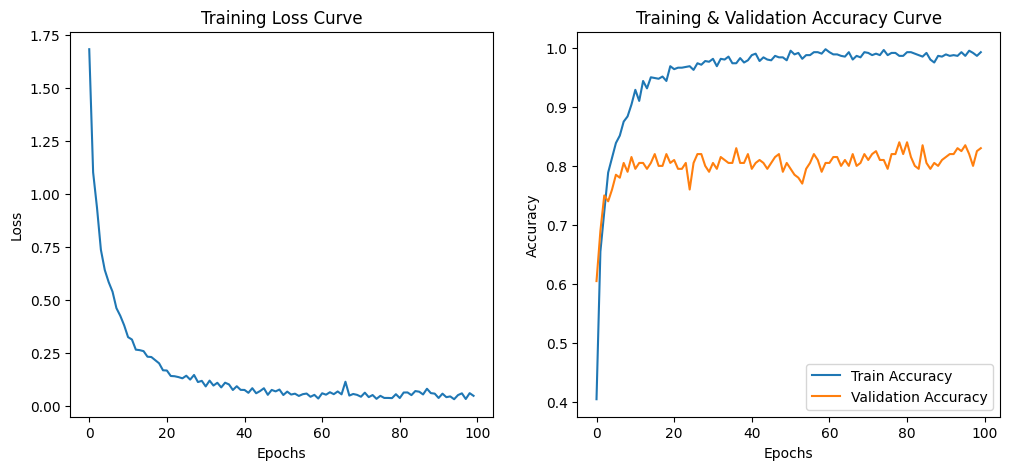

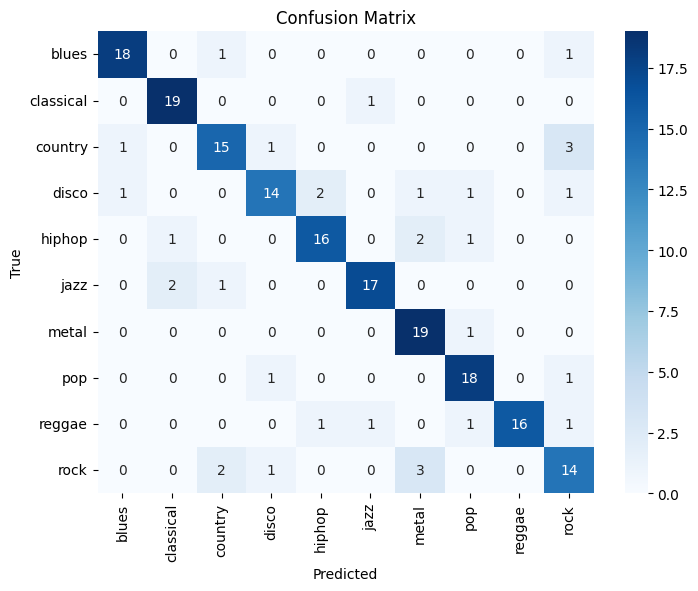

Precision: 0.8358
Recall: 0.8300
F1 Score: 0.8296


In [21]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
from torch.utils.data import DataLoader, TensorDataset
import seaborn as sns

# Set device (CUDA if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define MLP Model based on Optuna best trial
class MLPModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes, dropout_rate):
        super(MLPModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, hidden_dim // 2)
        self.bn3 = nn.BatchNorm1d(hidden_dim // 2)
        self.out = nn.Linear(hidden_dim // 2, num_classes)
        self.dropout = nn.Dropout(dropout_rate)

    def forward(self, x):
        x = F.silu(self.bn1(self.fc1(x)))  # Swish activation function
        x = self.dropout(x)
        x = F.silu(self.bn2(self.fc2(x)))
        x = self.dropout(x)
        x = F.silu(self.bn3(self.fc3(x)))
        x = self.out(x)
        return x

# Hyperparameters from Optuna best trial
hidden_dim = 1010
dropout_rate = 0.313540631366658
lr = 0.00042225414590705407
batch_size = 128

# Define the class names
classes = ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']

# Prepare data loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256)

# Initialize model
model = MLPModel(X_train.shape[1], hidden_dim, len(classes), dropout_rate).to(device)

# Optimizer and loss function
optimizer = optim.AdamW(model.parameters(), lr=lr)
criterion = nn.CrossEntropyLoss()

# Initialize lists for tracking metrics
train_losses = []
train_accuracies = []
val_accuracies = []

# Training loop (for 100 epochs)
epochs = 100
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    correct_preds = 0
    total_preds = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)  # Move data to the device
        optimizer.zero_grad()
        output = model(xb)
        loss = criterion(output, yb)
        loss.backward()
        optimizer.step()

        # Track loss and accuracy
        epoch_loss += loss.item()
        preds = output.argmax(dim=1)
        correct_preds += (preds == yb).sum().item()
        total_preds += yb.size(0)

    # Compute training accuracy for the epoch
    train_loss = epoch_loss / len(train_loader)
    train_accuracy = correct_preds / total_preds
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    # Validation accuracy after each epoch
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb).argmax(dim=1)
            all_preds.extend(preds.tolist())
            all_labels.extend(yb.tolist())

    val_accuracy = accuracy_score(all_labels, all_preds)
    val_accuracies.append(val_accuracy)
    print(f"Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f} - Train Accuracy: {train_accuracy:.4f} - Validation Accuracy: {val_accuracy:.4f}")

# Plotting loss and accuracy curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(range(epochs), train_losses, label='Train Loss')
plt.title('Training Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.subplot(1, 2, 2)
plt.plot(range(epochs), train_accuracies, label='Train Accuracy')
plt.plot(range(epochs), val_accuracies, label='Validation Accuracy')
plt.title('Training & Validation Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.show()

# Confusion Matrix and Precision/Recall/F1 score after training
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb, yb = xb.to(device), yb.to(device)
        preds = model(xb).argmax(dim=1)
        all_preds.extend(preds.tolist())
        all_labels.extend(yb.tolist())

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Precision, Recall, and F1 Score
precision = precision_score(all_labels, all_preds, average='weighted')
recall = recall_score(all_labels, all_preds, average='weighted')
f1 = f1_score(all_labels, all_preds, average='weighted')

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")


Epoch 1/100 - Train Loss: 2.2897 - Train Accuracy: 0.1525 - Validation Accuracy: 0.3250
Epoch 2/100 - Train Loss: 2.0848 - Train Accuracy: 0.2913 - Validation Accuracy: 0.4250
Epoch 3/100 - Train Loss: 1.9368 - Train Accuracy: 0.4025 - Validation Accuracy: 0.4450
Epoch 4/100 - Train Loss: 1.8066 - Train Accuracy: 0.4738 - Validation Accuracy: 0.4950
Epoch 5/100 - Train Loss: 1.7342 - Train Accuracy: 0.4813 - Validation Accuracy: 0.5300
Epoch 6/100 - Train Loss: 1.6813 - Train Accuracy: 0.4975 - Validation Accuracy: 0.5600
Epoch 7/100 - Train Loss: 1.6303 - Train Accuracy: 0.5425 - Validation Accuracy: 0.5850
Epoch 8/100 - Train Loss: 1.5824 - Train Accuracy: 0.5700 - Validation Accuracy: 0.6400
Epoch 9/100 - Train Loss: 1.5329 - Train Accuracy: 0.5925 - Validation Accuracy: 0.6500
Epoch 10/100 - Train Loss: 1.5127 - Train Accuracy: 0.5962 - Validation Accuracy: 0.6550
Epoch 11/100 - Train Loss: 1.4890 - Train Accuracy: 0.6138 - Validation Accuracy: 0.6550
Epoch 12/100 - Train Loss: 1.4

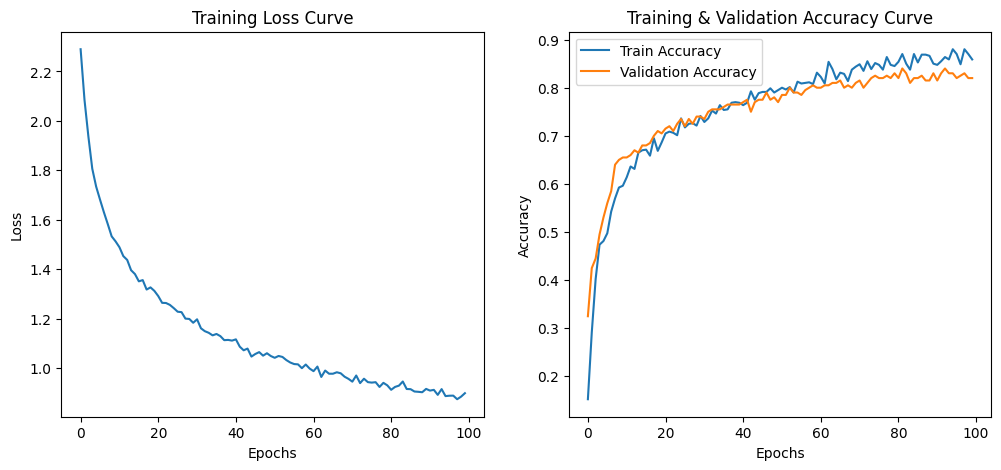

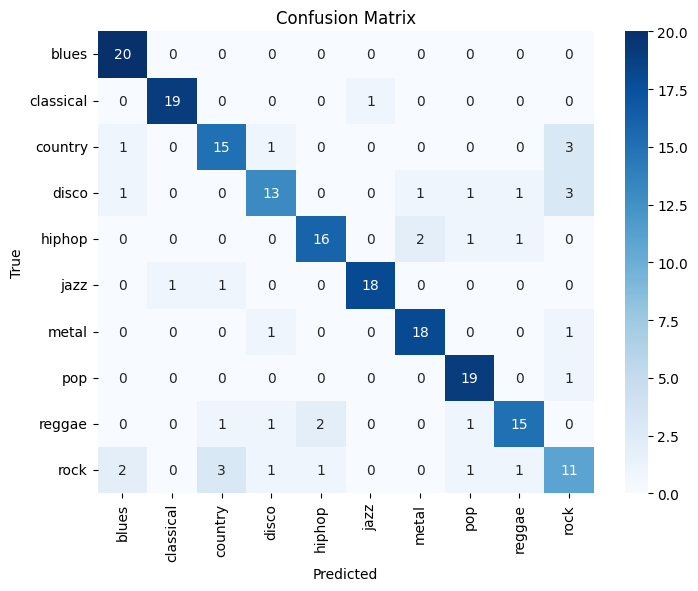

Precision: 0.8183
Recall: 0.8200
F1 Score: 0.8171


In [22]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
from torch.utils.data import DataLoader, TensorDataset
import seaborn as sns

# Set device (CUDA if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Define MLP Model based on Optuna best trial
class MLPModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes, dropout_rate):
        super(MLPModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, hidden_dim // 2)
        self.bn3 = nn.BatchNorm1d(hidden_dim // 2)
        self.out = nn.Linear(hidden_dim // 2, num_classes)
        self.dropout = nn.Dropout(dropout_rate)

    def forward(self, x):
        x = F.silu(self.bn1(self.fc1(x)))  # Swish activation function
        x = self.dropout(x)
        x = F.silu(self.bn2(self.fc2(x)))
        x = self.dropout(x)
        x = F.silu(self.bn3(self.fc3(x)))
        x = self.out(x)
        return x

# Hyperparameters from Optuna best trial
hidden_dim = 1018
dropout_rate = 0.3514
lr = 0.00033148281009519017
batch_size = 32

# Define the class names
classes = ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']

# Prepare data loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256)

# Initialize model
model = MLPModel(X_train.shape[1], hidden_dim, len(classes), dropout_rate).to(device)

# Optimizer and loss function
optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)  # Label smoothing added

# Initialize lists for tracking metrics
train_losses = []
train_accuracies = []
val_accuracies = []

# Training loop (for 100 epochs)
epochs = 100
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    correct_preds = 0
    total_preds = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)  # Move data to the device
        optimizer.zero_grad()
        output = model(xb)
        loss = criterion(output, yb)
        loss.backward()
        optimizer.step()

        # Track loss and accuracy
        epoch_loss += loss.item()
        preds = output.argmax(dim=1)
        correct_preds += (preds == yb).sum().item()
        total_preds += yb.size(0)

    # Compute training accuracy for the epoch
    train_loss = epoch_loss / len(train_loader)
    train_accuracy = correct_preds / total_preds
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    # Validation accuracy after each epoch
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb).argmax(dim=1)
            all_preds.extend(preds.tolist())
            all_labels.extend(yb.tolist())

    val_accuracy = accuracy_score(all_labels, all_preds)
    val_accuracies.append(val_accuracy)
    print(f"Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f} - Train Accuracy: {train_accuracy:.4f} - Validation Accuracy: {val_accuracy:.4f}")

# Plotting loss and accuracy curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(range(epochs), train_losses, label='Train Loss')
plt.title('Training Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.subplot(1, 2, 2)
plt.plot(range(epochs), train_accuracies, label='Train Accuracy')
plt.plot(range(epochs), val_accuracies, label='Validation Accuracy')
plt.title('Training & Validation Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.show()

# Confusion Matrix and Precision/Recall/F1 score after training
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb, yb = xb.to(device), yb.to(device)
        preds = model(xb).argmax(dim=1)
        all_preds.extend(preds.tolist())
        all_labels.extend(yb.tolist())

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Precision, Recall, and F1 Score
precision = precision_score(all_labels, all_preds, average='weighted')
recall = recall_score(all_labels, all_preds, average='weighted')
f1 = f1_score(all_labels, all_preds, average='weighted')

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
